# 분류모델(FISH_MARKET_KNN_모델02)
# 分类模型(FISH_MARKET_KNN_模型02)

**훈련 세트와 테스트 세트, 데이터 전처리 / 训练集与测试集、数据预处理**

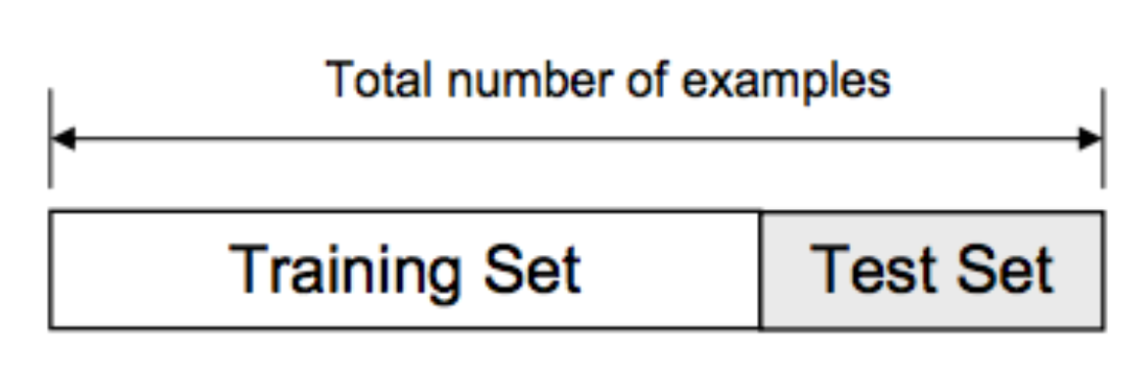

## 1번째 프로젝트 : 훈련 세트와 테스트 세트 (p68)
## 第1个项目：训练集与测试集 (p68)

In [ ]:
# 생선 49마리의 길이(cm) : 앞의 35개는 도미, 뒤의 14개는 빙어
# 49条鱼的长度(cm)：前35个是鲷鱼，后14个是胡瓜鱼
fish_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0, 9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
# 생선 49마리의 무게(g) : 길이와 같은 순서
# 49条鱼的重量(g)：与长度顺序相同
fish_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0, 6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [ ]:
# 길이 리스트 내용 확인
# 查看长度列表内容
fish_length

In [ ]:
# 무게 리스트 내용 확인
# 查看重量列表内容
fish_weight

In [ ]:
# 정답(타깃) : 도미는 1로 35개, 빙어는 0으로 14개 (글자 대신 숫자로 표시)
# 答案(目标)：鲷鱼用1表示35个，胡瓜鱼用0表示14个（用数字代替文字）
fish_target=[1]*35+[0]*14

In [ ]:
# [주의] 리스트를 + 로 더하면 짝이 아니라 그냥 이어 붙여진다 (잘못된 방법이라 주석 처리)
# [注意] 列表用 + 相加只会连接，不会配对（错误的方法，所以注释掉）
# fish_data=fish_length+fish_weight

In [ ]:
# zip()으로 길이와 무게를 짝지어 [길이, 무게] 쌍의 리스트를 만든다
# 用 zip() 把长度和重量配对，生成 [长度, 重量] 对的列表
fish_data=[[l,w] for l, w in zip(fish_length, fish_weight)]

In [ ]:
# 전체 샘플 수 : [길이, 무게] 1쌍이 생선 1마리 (49개)
# 样本总数：1对 [长度, 重量] 就是1条鱼（49个）
len(fish_data)

In [ ]:
# 사이킷런에서 KNN 분류기를 불러온다
# 从 sklearn 导入 KNN 分类器
from sklearn.neighbors import KNeighborsClassifier
# KNN 모델(객체)을 만든다 (기본 이웃 수 = 5)
# 创建 KNN 模型（对象）（默认邻居数 = 5）
kn=KNeighborsClassifier()

In [ ]:
# 입력된 데이터 확인하기
# 查看输入的数据
fish_data

In [ ]:
# 인덱스 1번(두 번째) 생선 출력 : 인덱스는 0부터 시작한다
# 输出索引1（第二条）鱼：索引从0开始
print(fish_data[1])

In [ ]:
# 인덱스 0번(첫 번째) 생선 출력
# 输出索引0（第一条）鱼
print(fish_data[0])

In [ ]:
# 인덱스 4번(다섯 번째) 생선 출력
# 输出索引4（第五条）鱼
print(fish_data[4])

In [ ]:
# 슬라이싱 [0:5] : 0번부터 4번까지 5개 출력 (끝 번호 5는 포함 안 됨)
# 切片 [0:5]：输出0到4号共5个（不包括结尾的5号）
print(fish_data[0:5])

In [ ]:
# 시작 번호를 생략하면 처음(0)부터 : 위와 같은 결과
# 省略开始编号就从头(0)开始：结果与上面相同
print(fish_data[:5])

In [ ]:
# 끝 번호를 생략하면 마지막까지 : 44번부터 끝까지 출력
# 省略结尾编号就到最后：输出44号到最后
print(fish_data[44:])

In [ ]:
# 훈련 입력 : 0번 ~ 34번 (35개)
# 训练输入：0号 ~ 34号（35个）
train_input=fish_data[:35]

In [ ]:
# 훈련 정답 : 0번 ~ 34번 (35개)
# 训练答案：0号 ~ 34号（35个）
train_target=fish_target[:35]

In [ ]:
# 테스트 입력 : 35번 ~ 마지막 (14개)
# 测试输入：35号 ~ 最后（14个）
test_input=fish_data[35:]

In [ ]:
# 테스트 정답 : 35번 ~ 마지막 (14개)
# 测试答案：35号 ~ 最后（14个）
test_target=fish_target[35:]

In [ ]:
# 훈련 세트로 모델을 훈련시킨다
# 用训练集训练模型
kn=kn.fit(train_input,train_target)
# 테스트 세트로 정확도를 평가한다
# 用测试集评估准确率
kn.score(test_input,test_target)

**정확도 0.0 ?!** 왜 그럴까? 아래 그래프로 확인해 보자.
**准确率 0.0 ?!** 为什么？用下面的图表来确认一下。

In [ ]:
# matplotlib와 numpy를 불러온다
# 导入 matplotlib 和 numpy
import matplotlib.pyplot as plt
import numpy as np
# 위와 같은 49마리 [길이, 무게] 데이터
# 与上面相同的49条鱼 [长度, 重量] 数据
data = [[25.4, 242.0], [26.3, 290.0], [26.5, 340.0], [29.0, 363.0], [29.0, 430.0], [29.7, 450.0], [29.7, 500.0], [30.0, 390.0], [30.0, 450.0], [30.7, 500.0], [31.0, 475.0], [31.0, 500.0], [31.5, 500.0], [32.0, 340.0], [32.0, 600.0], [32.0, 600.0], [33.0, 700.0], [33.0, 700.0], [33.5, 610.0], [33.5, 650.0], [34.0, 575.0], [34.0, 685.0], [34.5, 620.0], [35.0, 680.0], [35.0, 700.0], [35.0, 725.0], [35.0, 720.0], [36.0, 714.0], [36.0, 850.0], [37.0, 1000.0], [38.5, 920.0], [38.5, 955.0], [39.5, 925.0], [41.0, 975.0], [41.0, 950.0], [9.8, 6.7], [10.5, 7.5], [10.6, 7.0], [11.0, 9.7], [11.2, 9.8], [11.3, 8.7], [11.8, 10.0], [11.8, 9.9], [12.0, 9.8], [12.2, 12.2], [12.4, 13.4], [13.0, 12.2], [14.3, 19.7], [15.0, 19.9]]
# 앞 35개(도미)는 훈련용, 뒤 14개(빙어)는 테스트용으로 나눈다
# 前35个(鲷鱼)用于训练，后14个(胡瓜鱼)用于测试
train_data = data[:35]
test_data = data[35:]
# zip(*) : [길이, 무게] 쌍을 길이 묶음과 무게 묶음으로 풀어 준다
# zip(*)：把 [长度, 重量] 对拆成长度组和重量组
train_length, train_weight = zip(*train_data)
test_length, test_weight = zip(*test_data)
# 그래프 크기 지정
# 指定图表大小
plt.figure(figsize=(10, 6))
# 훈련 세트(도미)는 파란 점, 테스트 세트(빙어)는 빨간 점
# 训练集(鲷鱼)为蓝点，测试集(胡瓜鱼)为红点
plt.scatter(train_length, train_weight, c='blue', label='Train (Bream)')
plt.scatter(test_length, test_weight, c='red', label='Test (Smelt)')
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (cm)')
plt.ylabel('Weight (g)')
plt.title('Biased Data Split: Bream (Train) vs Smelt (Test)')
plt.legend()
# 그래프 보여주기
# 显示图表
plt.show()

→ 훈련 세트에는 도미만, 테스트 세트에는 빙어만 있다 (**샘플링 편향**). 모델은 빙어를 한 번도 배우지 못했다.
→ 训练集里只有鲷鱼，测试集里只有胡瓜鱼（**抽样偏差**）。模型从来没有学过胡瓜鱼。

해결 방법 : 데이터를 무작위로 섞어서 나눈다.
解决方法：把数据随机打乱后再分割。

In [ ]:
# numpy를 np라는 짧은 이름으로 불러온다
# 以简称 np 导入 numpy
import numpy as np

In [ ]:
# 리스트를 numpy 배열로 바꾼다 (행·열 구조의 2차원 배열)
# 把列表转换为 numpy 数组（有行和列的二维数组）
input_arr=np.array(fish_data)
# 정답 리스트도 numpy 배열로 바꾼다
# 把答案列表也转换为 numpy 数组
target_arr=np.array(fish_target)

In [ ]:
# 2차원 배열로 바뀐 생선 데이터 출력
# 输出转换为二维数组后的鱼数据
print(input_arr)

In [ ]:
# 비교 : 원래 리스트는 이렇게 출력된다
# 对比：原来的列表是这样输出的
print(fish_data)

In [ ]:
# shape : (샘플 수, 특성 수) = (49마리, 2개 특성[길이, 무게])
# shape：(样本数, 特征数) = (49条鱼, 2个特征[长度, 重量])
print(input_arr.shape)

In [ ]:
# 난수 seed를 고정한다 : 같은 숫자를 쓰면 누구나 같은 순서로 섞인다
# 固定随机种子：使用相同数字，任何人都会得到相同的打乱顺序
np.random.seed(55)
# 0부터 48까지 1씩 증가하는 번호(인덱스) 49개를 만든다
# 生成0到48、每次加1的49个编号(索引)
index=np.arange(49)
# 번호를 무작위로 섞는다
# 随机打乱编号
np.random.shuffle(index)

In [ ]:
# 섞인 번호를 확인한다
# 查看打乱后的编号
print(index)

In [ ]:
# 배열 인덱싱 : 1번과 3번 행을 한 번에 꺼낸다
# 数组索引：一次取出1号和3号行
print(input_arr[[1,3]])

In [ ]:
# 섞인 번호의 앞 35개로 훈련 입력을 만든다
# 用打乱后编号的前35个制作训练输入
train_input=input_arr[index[:35]]
# 같은 번호로 훈련 정답을 만든다 (입력과 정답의 짝이 유지된다)
# 用相同编号制作训练答案（输入和答案保持配对）
train_target=target_arr[index[:35]]

In [ ]:
# 확인 : 섞인 번호의 첫 번째(index[0]) 원래 데이터와 훈련 세트의 0번 데이터가 같다
# 确认：打乱编号中第一个(index[0])的原始数据与训练集0号数据相同
print(input_arr[index[0]], train_input[0])

In [ ]:
# 섞인 번호의 나머지 14개(35번~끝)로 테스트 입력을 만든다
# 用打乱编号中剩下的14个(35号~最后)制作测试输入
test_input=input_arr[index[35:]]
# 같은 번호로 테스트 정답을 만든다
# 用相同编号制作测试答案
test_target=target_arr[index[35:]]

In [ ]:
# 그래프 도구를 불러온다
# 导入画图工具
import matplotlib.pyplot as plt
# 훈련 세트 : [:,0] = 모든 행의 0번 열(길이), [:,1] = 1번 열(무게)
# 训练集：[:,0] = 所有行的第0列(长度)，[:,1] = 第1列(重量)
plt.scatter(train_input[:,0], train_input[:,1], label='Train')
# 테스트 세트를 점으로 찍는다
# 画出测试集数据点
plt.scatter(test_input[:,0], test_input[:,1], label='Test')
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (cm)')
plt.ylabel('Weight (g)')
plt.title('Shuffled Train / Test Split')
plt.legend()
# 그래프 보여주기 : 이제 두 세트 모두 도미와 빙어가 섞여 있다
# 显示图表：现在两个集合里都混有鲷鱼和胡瓜鱼
plt.show()

In [ ]:
# 섞은 훈련 세트로 다시 훈련한다
# 用打乱后的训练集重新训练
kn=kn.fit(train_input, train_target)
# 테스트 세트로 정확도를 평가한다
# 用测试集评估准确率
kn.score(test_input,test_target)

In [ ]:
# 훈련 세트에 대한 정확도도 확인한다
# 也确认一下对训练集的准确率
kn.score(train_input,train_target)

In [ ]:
# 테스트 샘플 수 확인 (14개)
# 确认测试样本数（14个）
len(test_input)

In [ ]:
# 테스트 입력 데이터 확인
# 查看测试输入数据
test_input

In [ ]:
# 테스트 입력으로 생선 종류를 예측해 본다
# 用测试输入预测鱼的种类
kn.predict(test_input)

In [ ]:
# 실제 정답과 비교한다 : 예측과 같으면 정답!
# 与实际答案对比：和预测相同就是正确！
test_target

## 2번째 프로젝트 : 데이터 전처리 (p79)
## 第2个项目：数据预处理 (p79)

In [ ]:
# 생선의 길이(cm) 입력
# 输入鱼的长度(cm)
fish_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0, 9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]

In [ ]:
# 생선의 무게(g) 입력
# 输入鱼的重量(g)
fish_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0, 6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [ ]:
# numpy 라이브러리를 np라는 짧은 이름으로 불러온다
# 以简称 np 导入 numpy 库
import numpy as np

In [ ]:
# column_stack : 리스트를 세로 열로 세워 나란히 붙인다 (1-4, 2-5, 3-6이 짝이 됨)
# column_stack：把列表竖成列并排拼接（1-4、2-5、3-6 配对）
np.column_stack(([1,2,3],[4,5,6]))

In [ ]:
# 길이와 무게를 열로 붙여 (49, 2) 모양의 배열을 만든다
# 把长度和重量按列拼接，生成 (49, 2) 形状的数组
fish_data=np.column_stack((fish_length,fish_weight))

In [ ]:
# 앞의 5개 내용 확인
# 查看前5个内容
print(fish_data[:5])

In [ ]:
# np.ones(5) : 1을 5개 만든다 (np.zeros 는 0을 만든다)
# np.ones(5)：生成5个1（np.zeros 生成0）
print(np.ones(5))

In [ ]:
# concatenate : 1이 35개(도미), 0이 14개(빙어)인 배열을 옆으로 길게 이어 붙인다
# concatenate：把35个1(鲷鱼)和14个0(胡瓜鱼)横向连接成一个长数组
fish_target=np.concatenate((np.ones(35),np.zeros(14)))

In [ ]:
# 정답 배열 확인
# 查看答案数组
print(fish_target)

In [ ]:
# train_test_split : 데이터를 훈련 세트와 테스트 세트로 알아서 섞어 나눠 준다 (기본 75% : 25%)
# train_test_split：自动打乱并把数据分成训练集和测试集（默认 75% : 25%）
from sklearn.model_selection import train_test_split

In [ ]:
# 입력·정답을 나눠 4개 결과로 받는다 / stratify : 도미·빙어 비율을 유지 / random_state : 섞는 방식 고정
# 拆分输入和答案并得到4个结果 / stratify：保持鲷鱼和胡瓜鱼的比例 / random_state：固定打乱方式
train_input, test_input, train_target, test_target = train_test_split(fish_data, fish_target, stratify=fish_target, random_state=42)

In [ ]:
# 테스트 정답 확인
# 查看测试答案
test_target

In [ ]:
# 전체 데이터 확인
# 查看全部数据
fish_data

In [ ]:
# 훈련 입력 (36, 2), 테스트 입력 (13, 2) : 36개와 13개, 특성은 2개(길이, 무게)
# 训练输入 (36, 2)，测试输入 (13, 2)：36个和13个，特征2个(长度, 重量)
print(train_input.shape, test_input.shape)

In [ ]:
# 훈련 정답 36개, 테스트 정답 13개
# 训练答案36个，测试答案13个
print(train_target.shape, test_target.shape)

In [ ]:
# 테스트 정답 : 빙어(0) 4개, 도미(1) 9개 → 전체 비율(빙어 14 : 도미 35)과 비슷하게 나뉨
# 测试答案：胡瓜鱼(0) 4个，鲷鱼(1) 9个 → 与整体比例(胡瓜鱼14 : 鲷鱼35)相近
print(test_target)

In [ ]:
# 비교 : stratify 없이 random_state=100 으로 나눠 본다 → 비율이 치우칠 수 있다
# 对比：不用 stratify，用 random_state=100 分割 → 比例可能会偏
train_input, test_input, train_target, test_target = train_test_split(fish_data, fish_target, random_state=100)

In [ ]:
# 테스트 정답 확인 : 빙어와 도미가 몇 마리인지 세어 보자 (이번에는 빙어 4, 도미 9)
# 查看测试答案：数一数有几条胡瓜鱼和鲷鱼（这次是胡瓜鱼4、鲷鱼9）
test_target

In [ ]:
# 훈련 정답 확인
# 查看训练答案
train_target

In [ ]:
# KNN 분류기를 불러온다
# 导入 KNN 分类器
from sklearn.neighbors import KNeighborsClassifier
# KNN 모델을 만든다
# 创建 KNN 模型
kn=KNeighborsClassifier()

In [ ]:
# 훈련 세트로 훈련한다
# 用训练集训练
kn=kn.fit(train_input, train_target)
# 테스트 세트 정확도
# 测试集准确率
kn.score(test_input,test_target)

In [ ]:
# 훈련 세트 정확도
# 训练集准确率
kn.score(train_input,train_target)

**(실습) random_state 값을 바꿔서(예: 140, 34) 다시 나눠 보고, 테스트 세트의 비율이 어떻게 달라지는지 확인해 보세요.**
**（练习）修改 random_state 值（例：140、34）重新分割，看看测试集的比例有什么变化。**

In [ ]:
# stratify로 비율을 유지하면서 random_state=140 으로 나눈다 (숫자를 바꿔서 실습)
# 用 stratify 保持比例，并用 random_state=140 分割（修改数字进行练习）
train_input, test_input, train_target, test_target = train_test_split(fish_data, fish_target, stratify=fish_target, random_state=140)

In [ ]:
# 테스트 정답 확인 : stratify 덕분에 random_state를 바꿔도 빙어 4, 도미 9 비율이 유지된다
# 查看测试答案：多亏 stratify，即使改变 random_state 也保持胡瓜鱼4、鲷鱼9的比例
test_target

## 수상한 도미 한 마리
## 一条可疑的鲷鱼

In [ ]:
# KNN 분류기를 불러온다
# 导入 KNN 分类器
from sklearn.neighbors import KNeighborsClassifier
# 모델을 만든다
# 创建模型
kn = KNeighborsClassifier()
# 훈련한다
# 训练
kn.fit(train_input, train_target)
# 테스트 세트로 성능(정확도)을 검증한다
# 用测试集验证性能（准确率）
kn.score(test_input, test_target)

In [ ]:
# 길이 25cm, 무게 150g인 생선은 도미(1)일까 빙어(0)일까? → 결과는 빙어(0)
# 长度25cm、重量150g的鱼是鲷鱼(1)还是胡瓜鱼(0)？→ 结果是胡瓜鱼(0)
print(kn.predict([[25, 150]]))

In [ ]:
# 차트로 확인하기 위해 그래프 도구를 불러온다
# 为了用图表确认，导入画图工具
import matplotlib.pyplot as plt

In [ ]:
# 훈련 데이터를 점으로 찍는다
# 画出训练数据点
plt.scatter(train_input[:,0], train_input[:,1], label='Train')
# 수상한 생선(25, 150)을 삼각형으로 표시한다
# 用三角形标出可疑的鱼(25, 150)
plt.scatter(25, 150, marker='^', label='Suspicious Fish')
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (cm)')
plt.ylabel('Weight (g)')
plt.title('Suspicious Fish (25 cm, 150 g)')
plt.legend()
# 그래프 보여주기
# 显示图表
plt.show()

In [ ]:
# kneighbors : 가장 가까운 이웃 5개의 거리와 인덱스를 구한다 (왜 빙어로 판단했는지 확인)
# kneighbors：求最近5个邻居的距离和索引（确认为什么判断为胡瓜鱼）
distances, indexes = kn.kneighbors([[25, 150]])

In [ ]:
# 훈련 데이터를 점으로 찍는다
# 画出训练数据点
plt.scatter(train_input[:,0], train_input[:,1], label='Train')
# 수상한 생선을 삼각형으로 표시한다
# 用三角形标出可疑的鱼
plt.scatter(25, 150, marker='^', label='Suspicious Fish')
# 가까운 이웃 5개를 마름모(D)로 표시한다
# 用菱形(D)标出最近的5个邻居
plt.scatter(train_input[indexes,0], train_input[indexes,1], marker='D', label='Nearest Neighbors')
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (cm)')
plt.ylabel('Weight (g)')
plt.title('5 Nearest Neighbors')
plt.legend()
# 그래프 보여주기 : 이웃 대부분이 빙어 쪽에 있다
# 显示图表：大部分邻居都在胡瓜鱼那边
plt.show()

In [ ]:
# 이웃 5마리의 [길이, 무게] 값
# 5个邻居的 [长度, 重量] 值
print(train_input[indexes])

In [ ]:
# 이웃 5마리의 정답 : 빙어(0) 4개, 도미(1) 1개 → 다수결로 빙어
# 5个邻居的答案：胡瓜鱼(0) 4个，鲷鱼(1) 1个 → 多数表决为胡瓜鱼
print(train_target[indexes])

In [ ]:
# 이웃까지의 거리 : 빙어 이웃 약 130~138, 도미 이웃 약 140 → 거리가 거의 무게 차이로만 결정된다
# 到邻居的距离：胡瓜鱼邻居约130~138，鲷鱼邻居约140 → 距离几乎只由重量差决定
print(distances)

## 기준을 맞춰라 (데이터 스케일)
## 统一标准（数据尺度）

- x축(길이)은 10~40, y축(무게)은 0~1000 → 범위가 달라서 거리가 무게에 크게 좌우된다.
- x轴(长度)是10~40，y轴(重量)是0~1000 → 范围不同，距离主要被重量左右。

In [ ]:
# [원래 그림] 훈련 데이터, 수상한 생선, 이웃 5개
# [原图] 训练数据、可疑的鱼、5个邻居
plt.scatter(train_input[:,0], train_input[:,1], label='Train')
plt.scatter(25, 150, marker='^', label='Suspicious Fish')
plt.scatter(train_input[indexes,0], train_input[indexes,1], marker='D', label='Nearest Neighbors')
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (cm)')
plt.ylabel('Weight (g)')
plt.title('Original Scale')
plt.legend()
plt.show()

In [ ]:
# [바꾼 그림] 같은 내용을 그린다
# [修改后的图] 画相同的内容
plt.scatter(train_input[:,0], train_input[:,1], label='Train')
plt.scatter(25, 150, marker='^', label='Suspicious Fish')
plt.scatter(train_input[indexes,0], train_input[indexes,1], marker='D', label='Nearest Neighbors')
# x축 범위를 0~1000으로 늘려 y축과 같은 범위로 본다
# 把x轴范围扩大到0~1000，与y轴范围相同
plt.xlim((0, 1000))
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (cm)')
plt.ylabel('Weight (g)')
plt.title('Same Range on Both Axes (0-1000)')
plt.legend()
plt.show()

→ 길이는 거의 영향이 없다. 해결 방법 : **표준화** (표준점수 = (값 - 평균) / 표준편차)
→ 长度几乎没有影响。解决方法：**标准化**（标准分数 = (值 - 平均值) / 标准差）

In [ ]:
# 특성(열)별 평균을 구한다 (axis=0 : 세로 방향 = 열마다 계산)
# 按特征(列)求平均值（axis=0：纵向 = 每列计算）
mean = np.mean(train_input, axis=0)
# 특성(열)별 표준편차를 구한다
# 按特征(列)求标准差
std = np.std(train_input, axis=0)

In [ ]:
# 평균과 표준편차 출력 : [길이, 무게] 순서
# 输出平均值和标准差：按 [长度, 重量] 顺序
print(mean, std)

In [ ]:
# 표준화 : 모든 값에서 평균을 빼고 표준편차로 나눈다 (numpy가 모든 행에 자동 적용)
# 标准化：所有值减去平均值再除以标准差（numpy 会自动应用到所有行）
train_scaled = (train_input - mean) / std

In [ ]:
# 표준화된 훈련 데이터 확인
# 查看标准化后的训练数据
train_scaled

## 전처리 데이터로 모델 훈련하기
## 用预处理后的数据训练模型

In [ ]:
# 표준화된 데이터를 점으로 찍는다
# 画出标准化后的数据点
plt.scatter(train_scaled[:,0], train_scaled[:,1], label='Train (scaled)')
# [주의] 수상한 생선은 아직 표준화하지 않아서 혼자 멀리 떨어져 보인다
# [注意] 可疑的鱼还没有标准化，所以看起来离得很远
plt.scatter(25, 150, marker='^', label='Suspicious Fish (not scaled)')
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (scaled)')
plt.ylabel('Weight (scaled)')
plt.title('Scaled Train Data vs Unscaled Sample')
plt.legend()
plt.show()

In [ ]:
# 수상한 생선도 훈련 세트의 평균·표준편차로 똑같이 표준화한다
# 可疑的鱼也用训练集的平均值和标准差同样标准化
new = ([25, 150] - mean) / std

In [ ]:
# 표준화된 값 확인
# 查看标准化后的值
new

In [ ]:
# 표준화된 훈련 데이터
# 标准化后的训练数据
plt.scatter(train_scaled[:,0], train_scaled[:,1], label='Train (scaled)')
# 표준화된 수상한 생선
# 标准化后的可疑的鱼
plt.scatter(new[0], new[1], marker='^', label='Suspicious Fish (scaled)')
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (scaled)')
plt.ylabel('Weight (scaled)')
plt.title('Both Scaled')
plt.legend()
plt.show()

In [ ]:
# 표준화한 데이터로 다시 훈련한다
# 用标准化后的数据重新训练
kn.fit(train_scaled, train_target)

In [ ]:
# 테스트 세트도 반드시 훈련 세트의 평균·표준편차로 표준화한다
# 测试集也必须用训练集的平均值和标准差进行标准化
test_scaled = (test_input - mean) / std

In [ ]:
# 테스트 정확도 확인 : 정확도는 그대로 1.0
# 确认测试准确率：准确率仍是1.0
kn.score(test_scaled, test_target)

In [ ]:
# 수상한 생선을 다시 예측 → 이번에는 도미(1)! (표준화 전에는 빙어(0)였다)
# 再次预测可疑的鱼 → 这次是鲷鱼(1)！（标准化前是胡瓜鱼(0)）
print(kn.predict([new]))

In [ ]:
# 표준화된 기준으로 가까운 이웃 5개를 다시 찾는다
# 按标准化后的标准重新寻找最近的5个邻居
distances, indexes = kn.kneighbors([new])

In [ ]:
# 표준화된 훈련 데이터, 수상한 생선, 새로 찾은 이웃 5개를 그린다
# 画出标准化后的训练数据、可疑的鱼、新找到的5个邻居
plt.scatter(train_scaled[:,0], train_scaled[:,1], label='Train (scaled)')
plt.scatter(new[0], new[1], marker='^', label='Suspicious Fish (scaled)')
plt.scatter(train_scaled[indexes,0], train_scaled[indexes,1], marker='D', label='Nearest Neighbors')
# 축 이름, 제목, 범례
# 坐标轴名称、标题、图例
plt.xlabel('Length (scaled)')
plt.ylabel('Weight (scaled)')
plt.title('Nearest Neighbors after Scaling')
plt.legend()
# 그래프 보여주기 : 이제 이웃이 모두 도미이다
# 显示图表：现在邻居全部是鲷鱼
plt.show()